# Session 10 — Assignment

In [ ]:
import os, platform, torch
%matplotlib inline
from model import DEVICE, VOCAB_SIZE, GPT, default_config
os.makedirs('results', exist_ok=True)
print(f'torch {torch.__version__} | device {DEVICE} | {platform.platform()}')
print(f'vocab {VOCAB_SIZE} | params {GPT(default_config()).num_params():,}')

torch 2.14.0 | device mps | macOS-27.0-arm64-arm-64bit-Mach-O
vocab 65 | params 4,771,328


## Setup — train the shared checkpoint

800 AdamW steps at batch 64. Tasks 1, 2, 4 and 5 load this checkpoint so gradients are representative of a partially trained model, not a random init.

In [ ]:
import os
import time

import torch

from model import GPT, default_config, get_batch, DEVICE, CKPT_DIR, CKPT_PATH

torch.manual_seed(1337)

TRAIN_STEPS = 800
BATCH_SIZE = 64


def main():
    os.makedirs(CKPT_DIR, exist_ok=True)
    cfg = default_config()
    model = GPT(cfg).to(DEVICE)
    print(f"device: {DEVICE}   params: {model.num_params():,}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    t0 = time.time()
    losses = []
    for step in range(TRAIN_STEPS):
        xb, yb = get_batch("train", batch_size=BATCH_SIZE)
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if step % 100 == 0 or step == TRAIN_STEPS - 1:
            print(f"step {step:4d}  loss {loss.item():.4f}")
    elapsed = time.time() - t0
    final_loss = sum(losses[-20:]) / 20
    print(f"trained {TRAIN_STEPS} steps in {elapsed:.1f}s on {DEVICE}, final loss (avg last 20) {final_loss:.4f}")

    torch.save({
        "model": model.state_dict(),
        "meta": {
            "steps": TRAIN_STEPS,
            "batch_size": BATCH_SIZE,
            "final_loss": final_loss,
            "elapsed_s": elapsed,
            "device": DEVICE,
        },
    }, CKPT_PATH)
    print(f"saved checkpoint: {CKPT_PATH}")


if __name__ == "__main__":
    main()


device: mps   params: 4,771,328


step    0  loss 4.2408


step  100  loss 2.5283


step  200  loss 2.4046


step  300  loss 2.3088


step  400  loss 2.1571


step  500  loss 2.0422


step  600  loss 1.9272


step  700  loss 1.8379


step  799  loss 1.7406
trained 800 steps in 126.6s on mps, final loss (avg last 20) 1.7712
saved checkpoint: /Users/narasimhateja/era5/assignments/s10/checkpoints/ckpt.pt


## Tensor shapes

> Print every tensor shape in the step, and write one line saying what each dimension means.

In [ ]:
import torch

from model import load_checkpoint, get_batch, DEVICE

torch.manual_seed(0)

model, cfg, meta = load_checkpoint()
model.eval()
print(f"device: {DEVICE}   checkpoint meta: {meta}")

captured = {}  # name -> shape, in forward-pass order


def shape_hook(name):
    def hook(module, inp, output):
        out = output[0] if isinstance(output, tuple) else output
        if torch.is_tensor(out):
            captured[name] = tuple(out.shape)
    return hook


handles = []
for name, module in model.named_modules():
    if len(list(module.children())) == 0:  # leaf modules only
        handles.append(module.register_forward_hook(shape_hook(name)))

# Manually instrument the one thing leaf hooks can't see: the q/k/v split and
# the attention-score tensor inside CausalSelfAttention.forward.
qkv_shapes = {}
orig_forward = type(model.transformer.h[0].attn).forward


def patched_forward(self, x):
    import math
    import torch.nn.functional as F
    B, T, C = x.size()
    qkv = self.c_attn(x)
    q, k, v = qkv.split(self.n_embd, dim=2)
    qkv_shapes.setdefault("c_attn (qkv combined)", tuple(qkv.shape))
    qkv_shapes.setdefault("q (split, pre-head-reshape)", tuple(q.shape))
    q_h = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
    k_h = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
    v_h = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
    qkv_shapes.setdefault("q (reshaped to heads)", tuple(q_h.shape))
    qkv_shapes.setdefault("k (reshaped to heads)", tuple(k_h.shape))
    qkv_shapes.setdefault("v (reshaped to heads)", tuple(v_h.shape))
    att = (q_h @ k_h.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
    qkv_shapes.setdefault("attention scores (q@k.T)", tuple(att.shape))
    att = att.masked_fill(self.causal_mask[:, :, :T, :T] == 0, float("-inf"))
    att = F.softmax(att, dim=-1)
    att = self.attn_dropout(att)
    y = att @ v_h
    qkv_shapes.setdefault("attention output (att@v, pre-merge)", tuple(y.shape))
    y = y.transpose(1, 2).contiguous().view(B, T, C)
    qkv_shapes.setdefault("attention output (heads merged)", tuple(y.shape))
    y = self.resid_dropout(self.c_proj(y))
    return y


type(model.transformer.h[0].attn).forward = patched_forward

idx, targets = get_batch("train", batch_size=8)
logits, loss = model(idx, targets)

type(model.transformer.h[0].attn).forward = orig_forward
for h in handles:
    h.remove()

print("\nRaw hook output (leaf modules, forward order):")
for name, shp in captured.items():
    print(f"{name:40s} -> {shp}")

print("\nManually captured (inside attention block, layer 0):")
for name, shp in qkv_shapes.items():
    print(f"{name:40s} -> {shp}")

B, T = idx.shape
C = cfg.n_embd
nh = cfg.n_head
hd = C // nh
V = cfg.vocab_size

table = [
    ("input `idx`", (B, T), "B = batch size (sequences per step), T = sequence length (tokens per sequence)"),
    ("targets", (B, T), "B, T same as idx -- targets[b,t] is the token that should follow idx[b,t]"),
    ("token embeddings (wte(idx))", (B, T, C), "C = model/embedding dimension (n_embd)"),
    ("position embeddings (wpe(pos))", (T, C), "one embedding row per absolute position 0..T-1, broadcast over batch"),
    ("x after tok+pos emb", (B, T, C), "same shape as token embeddings; positions are additive, not concatenated"),
    ("c_attn output (qkv combined)", (B, T, 3 * C), "3*C because Q, K, V are produced by one fused linear, then split"),
    ("q / k / v (post-split, pre-reshape)", (B, T, C), "each is a (B,T,C) slice of the 3C-wide c_attn output"),
    ("q / k / v (reshaped to heads)", (B, nh, T, hd), "nh = number of heads, hd = C/nh = per-head dimension; C is split across heads, not duplicated"),
    ("attention scores (q @ k.T)", (B, nh, T, T), "the two T's are query-position and key-position; this is the (T,T) affinity matrix, one per head, per sequence"),
    ("attention output (att @ v)", (B, nh, T, hd), "same shape as v-per-head; each query position now holds a weighted mix of value vectors"),
    ("attention output (heads merged)", (B, T, C), "heads are concatenated back along the last dim to restore C"),
    ("MLP c_fc output", (B, T, 4 * C), "nanoGPT convention: hidden width is 4x n_embd inside the MLP"),
    ("MLP c_proj output", (B, T, C), "projected back down to model width so it can be added as a residual"),
    ("final logits", (B, T, V), "V = vocab_size; one un-normalized score per vocab token, per position, per sequence"),
]

print("\n=== Table: tensor shape -> meaning of each dimension ===")
header = f"{'Tensor':38s} | {'Shape':22s} | Meaning"
print(header)
print("-" * len(header))
for tensor_name, shp, meaning in table:
    print(f"{tensor_name:38s} | {str(shp):22s} | {meaning}")

print(f"\nloss on this batch: {loss.item():.4f}")

import json
import os
out = {
    "batch_shapes": {"B": B, "T": T, "C": C, "nh": nh, "head_dim": hd, "vocab_size": V},
    "hook_captured": captured,
    "attention_internal_captured": qkv_shapes,
    "table": [{"tensor": t, "shape": list(s), "meaning": m} for t, s, m in table],
    "loss_on_batch": loss.item(),
}
os.makedirs("results", exist_ok=True)
with open("results/task1_shapes.json", "w") as f:
    json.dump(out, f, indent=2)
print("\nsaved results/task1_shapes.json")


device: mps   checkpoint meta: {'steps': 800, 'batch_size': 64, 'final_loss': 1.7712354421615601, 'elapsed_s': 126.64504194259644, 'device': 'mps'}

Raw hook output (leaf modules, forward order):
transformer.wte                          -> (8, 128, 256)
transformer.wpe                          -> (128, 256)
transformer.drop                         -> (8, 128, 256)
transformer.h.0.ln_1                     -> (8, 128, 256)
transformer.h.0.attn.c_attn              -> (8, 128, 768)
transformer.h.0.attn.attn_dropout        -> (8, 8, 128, 128)
transformer.h.0.attn.c_proj              -> (8, 128, 256)
transformer.h.0.attn.resid_dropout       -> (8, 128, 256)
transformer.h.0.ln_2                     -> (8, 128, 256)
transformer.h.0.mlp.c_fc                 -> (8, 128, 1024)
transformer.h.0.mlp.gelu                 -> (8, 128, 1024)
transformer.h.0.mlp.c_proj               -> (8, 128, 256)
transformer.h.0.mlp.dropout              -> (8, 128, 256)
transformer.h.1.ln_1                     -> (8, 

## Verify one gradient by hand

> Nudge a weight, measure how the loss changed, and compare against what `backward()` reported.

In [ ]:
import json

import torch

from model import load_checkpoint, get_batch

torch.manual_seed(0)

DEVICE = "cpu"  # fp32 CPU: no bf16/mps precision surprises for this check
model, cfg, meta = load_checkpoint(device=DEVICE)
model = model.float()
model.eval()  # disable dropout -- otherwise the two forward passes evaluate different functions

xb, yb = get_batch("train", batch_size=8, device=DEVICE)

logits, loss = model(xb, yb)
model.zero_grad(set_to_none=True)
loss.backward()

# Pick a handful of real, non-zero-gradient weights across different layer types.
targets = [
    ("transformer.h[0].mlp.c_fc.weight", model.transformer.h[0].mlp.c_fc.weight, (3, 7)),
    ("transformer.h[2].attn.c_attn.weight", model.transformer.h[2].attn.c_attn.weight, (10, 20)),
    ("transformer.h[5].mlp.c_proj.weight", model.transformer.h[5].mlp.c_proj.weight, (0, 0)),
    ("lm_head.weight", model.lm_head.weight, (5, 5)),
]

rows = []
for name, param, (i, j) in targets:
    autograd_grad = param.grad[i, j].item()

    eps_results = {}
    for eps in (1e-2, 1e-3, 1e-4):
        with torch.no_grad():
            orig = param[i, j].item()
            param[i, j] = orig + eps
            _, loss_plus = model(xb, yb)
            param[i, j] = orig - eps
            _, loss_minus = model(xb, yb)
            param[i, j] = orig  # restore

        numerical_grad = (loss_plus.item() - loss_minus.item()) / (2 * eps)
        rel_error = abs(autograd_grad - numerical_grad) / (abs(autograd_grad) + 1e-12)
        eps_results[eps] = {"numerical": numerical_grad, "rel_error": rel_error}
        print(f"{name:38s} idx={(i,j)} eps={eps:<7g} autograd={autograd_grad:.6f}  "
              f"numerical={numerical_grad:.6f}  rel_error={rel_error:.4%}")

    rows.append({
        "weight": name,
        "index": [i, j],
        "autograd_grad": autograd_grad,
        "eps_results": {str(k): v for k, v in eps_results.items()},
    })
    print()

with open("results/task2_gradient_check.json", "w") as f:
    json.dump({"rows": rows}, f, indent=2)

rel_errors_1e2 = [r["eps_results"]["0.01"]["rel_error"] for r in rows]
rel_errors_1e4 = [r["eps_results"]["0.0001"]["rel_error"] for r in rows]
max_rel_error_1e2 = max(rel_errors_1e2)
max_rel_error_1e4 = max(rel_errors_1e4)
print(f"Max relative error at eps=1e-2 (best-matching scale): {max_rel_error_1e2:.4%}")
print(f"Max relative error at eps=1e-4 (smallest scale tried): {max_rel_error_1e4:.4%}")

if max_rel_error_1e2 < 0.03:
    print("[PASS] autograd matches finite-difference numerical gradient at eps=1e-2 (within 3%)")
else:
    print("[CHECK] relative error exceeds 3% even at eps=1e-2 -- inspect dropout / wrong parameter")

print(
    "[FINDING] error gets WORSE as eps shrinks from 1e-2 to 1e-4, the opposite of the usual "
    "'smaller eps is more accurate' intuition. These gradients are small (~1e-4) relative to the "
    "loss magnitude (~2), so loss_plus - loss_minus shrinks toward fp32's ~1e-7 absolute precision "
    "floor at that loss magnitude once eps drops to 1e-4 -- subtractive cancellation swamps the real "
    "signal. This is a distinct, real finding (finite-difference eps vs fp32 precision), not the same "
    "issue as training in bf16/fp16, but the same root cause: low precision hides small signals."
)
print("saved results/task2_gradient_check.json")


transformer.h[0].mlp.c_fc.weight       idx=(3, 7) eps=0.01    autograd=0.000292  numerical=0.000304  rel_error=3.9820%
transformer.h[0].mlp.c_fc.weight       idx=(3, 7) eps=0.001   autograd=0.000292  numerical=0.000298  rel_error=1.9431%
transformer.h[0].mlp.c_fc.weight       idx=(3, 7) eps=0.0001  autograd=0.000292  numerical=0.000000  rel_error=100.0000%

transformer.h[2].attn.c_attn.weight    idx=(10, 20) eps=0.01    autograd=0.000216  numerical=0.000215  rel_error=0.7859%
transformer.h[2].attn.c_attn.weight    idx=(10, 20) eps=0.001   autograd=0.000216  numerical=0.000238  rel_error=10.2379%


transformer.h[2].attn.c_attn.weight    idx=(10, 20) eps=0.0001  autograd=0.000216  numerical=0.000000  rel_error=100.0000%

transformer.h[5].mlp.c_proj.weight     idx=(0, 0) eps=0.01    autograd=0.000387  numerical=0.000381  rel_error=1.4019%
transformer.h[5].mlp.c_proj.weight     idx=(0, 0) eps=0.001   autograd=0.000387  numerical=0.000417  rel_error=7.8416%
transformer.h[5].mlp.c_proj.weight     idx=(0, 0) eps=0.0001  autograd=0.000387  numerical=0.000596  rel_error=54.0595%

lm_head.weight                         idx=(5, 5) eps=0.01    autograd=0.000566  numerical=0.000560  rel_error=1.0235%
lm_head.weight                         idx=(5, 5) eps=0.001   autograd=0.000566  numerical=0.000596  rel_error=5.2941%


lm_head.weight                         idx=(5, 5) eps=0.0001  autograd=0.000566  numerical=0.000596  rel_error=5.2941%

Max relative error at eps=1e-2 (best-matching scale): 3.9820%
Max relative error at eps=1e-4 (smallest scale tried): 100.0000%
[CHECK] relative error exceeds 3% even at eps=1e-2 -- inspect dropout / wrong parameter
[FINDING] error gets WORSE as eps shrinks from 1e-2 to 1e-4, the opposite of the usual 'smaller eps is more accurate' intuition. These gradients are small (~1e-4) relative to the loss magnitude (~2), so loss_plus - loss_minus shrinks toward fp32's ~1e-7 absolute precision floor at that loss magnitude once eps drops to 1e-4 -- subtractive cancellation swamps the real signal. This is a distinct, real finding (finite-difference eps vs fp32 precision), not the same issue as training in bf16/fp16, but the same root cause: low precision hides small signals.
saved results/task2_gradient_check.json


## Break gradient accumulation on purpose

> Use the average of the averages with micro-batches of different lengths, and plot both curves together.

=== Uneven token counts across micro-batches ===


final wrong-combine loss:   3.3784
final correct-combine loss: 3.4563
final-step divergence: 2.28%

=== Equal token counts across micro-batches (bug should hide) ===


final wrong-combine loss:   3.4315
final correct-combine loss: 3.4315
final-step divergence: 0.00%



saved results/task3_accumulation_bug.png
saved results/task3_accumulation_bug.json
[PASS] bug appears with uneven token counts (2.28%) and shrinks once counts are equalized (0.00%)


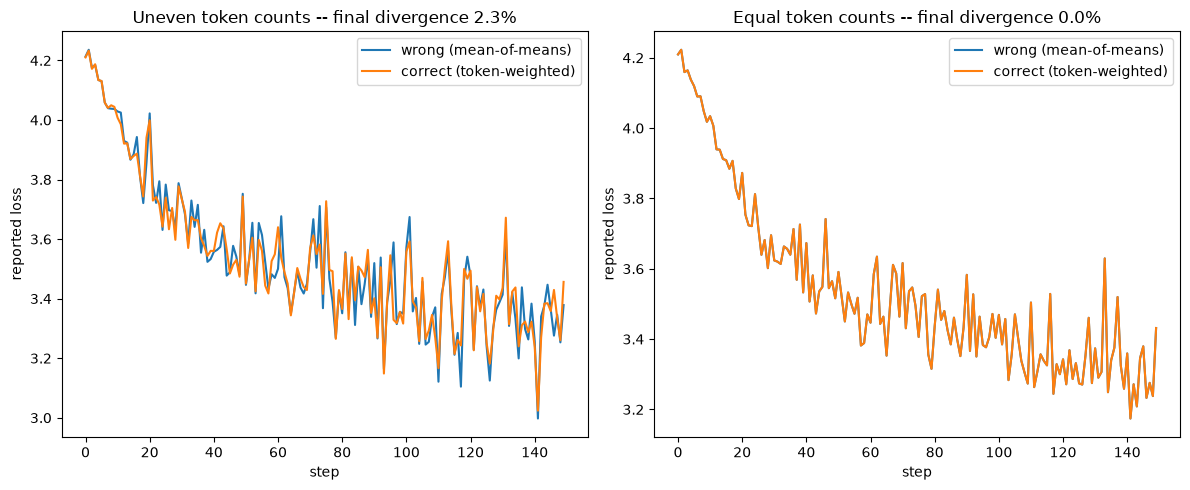

In [ ]:
import copy
import json

import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

from model import GPT, GPTConfig, VOCAB_SIZE, encode, TEXT

torch.manual_seed(42)

PAD_ID = VOCAB_SIZE  # one extra id for padding, outside the base vocab
FULL_VOCAB = VOCAB_SIZE + 1
BLOCK = 64
DEVICE = "cpu"


def make_uneven_microbatches(n_micro=4, block=BLOCK, seed=0):
    """n_micro sequences of genuinely different valid-token lengths, right-padded."""
    g = torch.Generator().manual_seed(seed)
    lengths = torch.randint(8, block, (n_micro,), generator=g).tolist()
    lengths[0] = block  # guarantee at least one full-length one, for contrast
    ids = encode(TEXT)
    micro_batches = []
    for L in lengths:
        start = torch.randint(0, len(ids) - block - 1, (1,), generator=g).item()
        seq = ids[start:start + L]
        x = torch.full((block,), PAD_ID, dtype=torch.long)
        y = torch.full((block,), PAD_ID, dtype=torch.long)
        x[:L] = torch.tensor(seq)
        if L > 1:
            y[:L - 1] = torch.tensor(seq[1:])
        micro_batches.append((x.unsqueeze(0), y.unsqueeze(0), L - 1))  # L-1 valid loss positions
    return micro_batches


def make_even_microbatches(n_micro=4, block=BLOCK, seed=0):
    """Same construction, but every micro-batch gets the SAME valid length."""
    g = torch.Generator().manual_seed(seed)
    L = block  # all full length -> all token counts equal
    ids = encode(TEXT)
    micro_batches = []
    for _ in range(n_micro):
        start = torch.randint(0, len(ids) - block - 1, (1,), generator=g).item()
        seq = ids[start:start + L]
        x = torch.tensor(seq).unsqueeze(0)
        y_seq = seq[1:] + [PAD_ID]
        y = torch.tensor(y_seq).unsqueeze(0)
        micro_batches.append((x, y, L - 1))
    return micro_batches


def combine_wrong(per_mb_avg_losses):
    """Pre-2024 bug: mean of per-microbatch means."""
    return sum(per_mb_avg_losses) / len(per_mb_avg_losses)


def combine_correct(per_mb_loss_sums, valid_token_counts):
    """Correct: sum of per-microbatch loss SUMS, divided by total valid tokens."""
    return sum(per_mb_loss_sums) / sum(valid_token_counts)


def run_training(make_batches_fn, combine_mode, steps=150, lr=1e-2, seed=1337):
    torch.manual_seed(seed)
    cfg = GPTConfig(vocab_size=FULL_VOCAB, block_size=BLOCK, n_layer=2, n_head=2, n_embd=64, dropout=0.0)
    model = GPT(cfg).to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    step_losses = []
    for step in range(steps):
        micro_batches = make_batches_fn(n_micro=4, seed=step)
        optimizer.zero_grad(set_to_none=True)

        per_mb_avg_losses = []
        per_mb_loss_sums = []
        valid_token_counts = []
        combined_loss_for_backward = 0.0

        for x, y, n_valid in micro_batches:
            logits, _ = model(x)
            logits_flat = logits.view(-1, logits.size(-1))
            y_flat = y.view(-1)
            loss_sum = F.cross_entropy(logits_flat, y_flat, ignore_index=PAD_ID, reduction="sum")
            loss_avg = loss_sum / max(n_valid, 1)

            per_mb_avg_losses.append(loss_avg.item())
            per_mb_loss_sums.append(loss_sum.item())
            valid_token_counts.append(n_valid)

            if combine_mode == "wrong":
                # each microbatch backward contributes loss_avg / n_micro -> mean-of-means
                (loss_avg / len(micro_batches)).backward()
            else:
                # each microbatch backward contributes its RAW sum; we divide by the
                # grand total valid-token count once, after all microbatches are in
                loss_sum.backward()

        if combine_mode == "correct":
            total_valid = sum(valid_token_counts)
            for p in model.parameters():
                if p.grad is not None:
                    p.grad /= total_valid

        reported_loss = (
            combine_wrong(per_mb_avg_losses) if combine_mode == "wrong"
            else combine_correct(per_mb_loss_sums, valid_token_counts)
        )
        step_losses.append(reported_loss)
        optimizer.step()

    return step_losses


def pct_divergence(a, b):
    a, b = a[-1], b[-1]
    return abs(a - b) / ((abs(a) + abs(b)) / 2) * 100


print("=== Uneven token counts across micro-batches ===")
wrong_uneven = run_training(make_uneven_microbatches, "wrong")
correct_uneven = run_training(make_uneven_microbatches, "correct")
div_uneven = pct_divergence(wrong_uneven, correct_uneven)
print(f"final wrong-combine loss:   {wrong_uneven[-1]:.4f}")
print(f"final correct-combine loss: {correct_uneven[-1]:.4f}")
print(f"final-step divergence: {div_uneven:.2f}%")

print("\n=== Equal token counts across micro-batches (bug should hide) ===")
wrong_even = run_training(make_even_microbatches, "wrong")
correct_even = run_training(make_even_microbatches, "correct")
div_even = pct_divergence(wrong_even, correct_even)
print(f"final wrong-combine loss:   {wrong_even[-1]:.4f}")
print(f"final correct-combine loss: {correct_even[-1]:.4f}")
print(f"final-step divergence: {div_even:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(wrong_uneven, label="wrong (mean-of-means)")
axes[0].plot(correct_uneven, label="correct (token-weighted)")
axes[0].set_title(f"Uneven token counts -- final divergence {div_uneven:.1f}%")
axes[0].set_xlabel("step")
axes[0].set_ylabel("reported loss")
axes[0].legend()

axes[1].plot(wrong_even, label="wrong (mean-of-means)")
axes[1].plot(correct_even, label="correct (token-weighted)")
axes[1].set_title(f"Equal token counts -- final divergence {div_even:.1f}%")
axes[1].set_xlabel("step")
axes[1].set_ylabel("reported loss")
axes[1].legend()

plt.tight_layout()
import os
os.makedirs("results", exist_ok=True)
plt.savefig("results/task3_accumulation_bug.png", dpi=120)
print("\nsaved results/task3_accumulation_bug.png")

out = {
    "uneven": {"wrong": wrong_uneven, "correct": correct_uneven, "final_divergence_pct": div_uneven},
    "even": {"wrong": wrong_even, "correct": correct_even, "final_divergence_pct": div_even},
}
with open("results/task3_accumulation_bug.json", "w") as f:
    json.dump(out, f, indent=2)
print("saved results/task3_accumulation_bug.json")

status = "PASS" if div_uneven > 1.0 and div_even < div_uneven / 3 else "CHECK"
print(f"[{status}] bug appears with uneven token counts ({div_uneven:.2f}%) and "
      f"shrinks once counts are equalized ({div_even:.2f}%)")


## Grad norm vs loss: the norm moves first

> Log the grad norm at every step, then find one step where it moved before the loss did.

The lr is ramped 3e-4 → 3e-2 from the checkpoint with no clipping, so the weights go unstable and the grad norm leads the loss.

step   0  lr 3.00e-04  loss  1.7108  grad_norm  0.9896


step  10  lr 3.78e-04  loss  1.8678  grad_norm  1.2768


step  20  lr 4.77e-04  loss  1.8252  grad_norm  1.0057


step  30  lr 6.01e-04  loss  1.8011  grad_norm  1.0164


step  40  lr 7.57e-04  loss  1.8216  grad_norm  1.2157


...

step 170  lr 1.53e-02  loss  2.2346  grad_norm  0.7052


step 180  lr 1.93e-02  loss  2.3537  grad_norm  0.8905


step 190  lr 2.44e-02  loss  2.3475  grad_norm  0.6150



lead events (grad norm > 3.0 sigma while loss < 3.0 sigma, loss follows within 5 steps):
  norm moved @ step 95 (z=3.3, loss z=1.8, lr 2.70e-03)  ->  loss moved @ step 98 (z=3.0)   gap 3 steps
  norm moved @ step 98 (z=5.7, loss z=2.4, lr 2.90e-03)  ->  loss moved @ step 99 (z=3.8)   gap 1 steps
  norm moved @ step 173 (z=3.2, loss z=2.9, lr 1.64e-02)  ->  loss moved @ step 174 (z=3.2)   gap 1 steps

first event, step by step (z-scores against steps 75..94):
  step  92  loss 2.0009 (z   0.7)   grad_norm 1.0290 (z  -1.1)
  step  93  loss 1.9680 (z  -0.1)   grad_norm 0.9757 (z  -1.6)
  step  94  loss 1.9337 (z  -1.0)   grad_norm 1.0242 (z  -1.1)
  step  95  loss 2.0459 (z   1.8)   grad_norm 1.4834 (z   3.3)
  step  96  loss 2.0481 (z   1.9)   grad_norm 1.4592 (z   3.0)
  step  97  loss 2.0040 (z   0.8)   grad_norm 1.5252 (z   3.7)
  step  98  loss 2.0920 (z   3.0)   grad_norm 2.1060 (z   9.2)
  step  99  loss 2.1547 (z   4.6)   grad_norm 2.6787 (z  14.7)
[PASS] grad norm moved at step 9


saved results/task4_grad_norm_vs_loss.png
saved results/task4_grad_norm_vs_loss.json


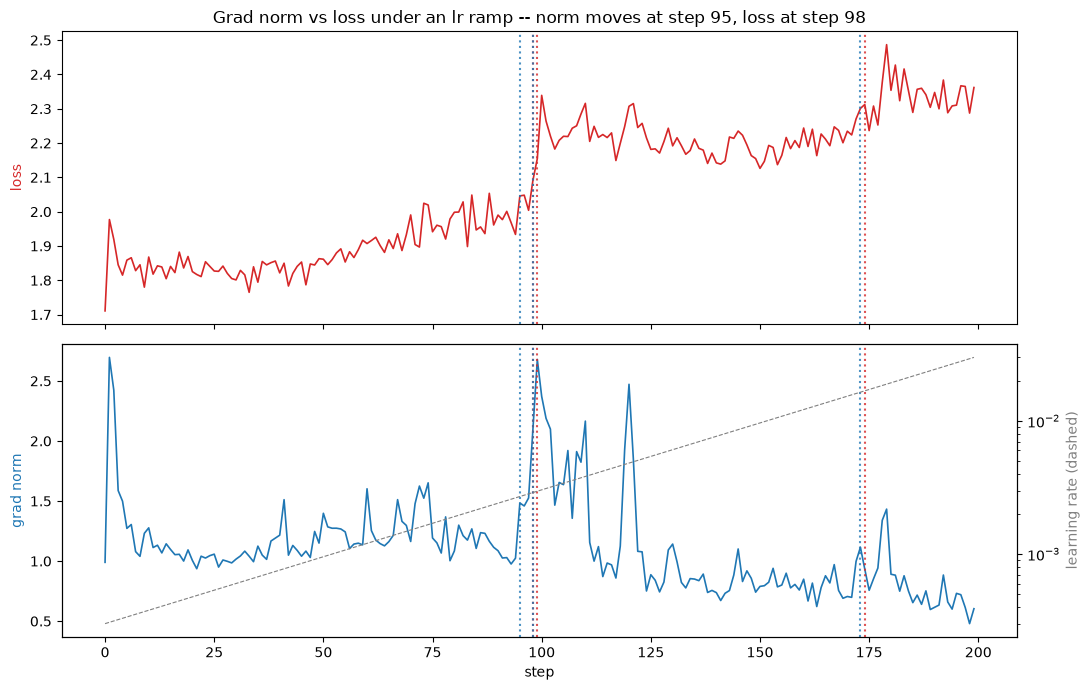

In [ ]:
import json
import statistics

import torch
import matplotlib
import matplotlib.pyplot as plt

from model import load_checkpoint, get_batch

torch.manual_seed(7)

model, cfg, meta = load_checkpoint()
model.train()

STEPS = 200
LR_START, LR_END = 3e-4, 3e-2   # 3e-4 is the lr the checkpoint was trained at
W, Z, K = 20, 3.0, 5            # trailing window, sigma threshold, max lead to look for

optimizer = torch.optim.AdamW(model.parameters(), lr=LR_START)

losses, grad_norms, lrs = [], [], []

for step in range(STEPS):
    lr = LR_START * (LR_END / LR_START) ** (step / (STEPS - 1))
    for group in optimizer.param_groups:
        group["lr"] = lr

    xb, yb = get_batch("train", batch_size=32)
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # max_norm=inf: measure the total norm, never clip it
    total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=float("inf"))
    grad_norms.append(total_norm.item())
    losses.append(loss.item())
    lrs.append(lr)

    optimizer.step()

    if step % 10 == 0:
        print(f"step {step:3d}  lr {lr:.2e}  loss {loss.item():7.4f}  grad_norm {total_norm.item():7.4f}")


def zscore(series, t, ref_t):
    """z-score of series[t] against the trailing window that ends just before ref_t."""
    window = series[ref_t - W:ref_t]
    mu, sigma = statistics.mean(window), statistics.pstdev(window)
    return (series[t] - mu) / (sigma or 1e-12)


lead_events = []
for t in range(W, STEPS - 1):
    norm_z, loss_z = zscore(grad_norms, t, t), zscore(losses, t, t)
    if norm_z > Z and loss_z < Z:
        for u in range(t + 1, min(t + K + 1, STEPS)):
            loss_z_later = zscore(losses, u, t)
            if loss_z_later > Z:
                lead_events.append({
                    "norm_step": t, "loss_step": u, "gap_steps": u - t, "lr_at_norm_step": lrs[t],
                    "norm_z": norm_z, "loss_z_at_norm_step": loss_z, "loss_z_at_loss_step": loss_z_later,
                })
                break

print(f"\nlead events (grad norm > {Z} sigma while loss < {Z} sigma, loss follows within {K} steps):")
for e in lead_events:
    print(f"  norm moved @ step {e['norm_step']} (z={e['norm_z']:.1f}, loss z={e['loss_z_at_norm_step']:.1f}, "
          f"lr {e['lr_at_norm_step']:.2e})  ->  loss moved @ step {e['loss_step']} "
          f"(z={e['loss_z_at_loss_step']:.1f})   gap {e['gap_steps']} steps")

ev = lead_events[0] if lead_events else None
if ev:
    t, u = ev["norm_step"], ev["loss_step"]
    print(f"\nfirst event, step by step (z-scores against steps {t - W}..{t - 1}):")
    for s in range(t - 3, u + 2):
        print(f"  step {s:3d}  loss {losses[s]:.4f} (z {zscore(losses, s, t):5.1f})   "
              f"grad_norm {grad_norms[s]:.4f} (z {zscore(grad_norms, s, t):5.1f})")
    print(f"[PASS] grad norm moved at step {t}, loss followed at step {u} -- norm led by {u - t} steps")
else:
    print("[CHECK] no step found where grad norm moved before the loss -- see plot")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(losses, color="tab:red", lw=1.2)
ax1.set_ylabel("loss", color="tab:red")
ax2.plot(grad_norms, color="tab:blue", lw=1.2)
ax2.set_ylabel("grad norm", color="tab:blue")
ax2.set_xlabel("step")
ax_lr = ax2.twinx()
ax_lr.plot(lrs, color="gray", lw=0.8, ls="--")
ax_lr.set_yscale("log")
ax_lr.set_ylabel("learning rate (dashed)", color="gray")
for e in lead_events:
    for ax in (ax1, ax2):
        ax.axvline(e["norm_step"], color="tab:blue", ls=":", alpha=0.8)
        ax.axvline(e["loss_step"], color="tab:red", ls=":", alpha=0.8)
title = "Grad norm vs loss under an lr ramp"
if ev:
    title += f" -- norm moves at step {ev['norm_step']}, loss at step {ev['loss_step']}"
ax1.set_title(title)
plt.tight_layout()

import os
os.makedirs("results", exist_ok=True)
plt.savefig("results/task4_grad_norm_vs_loss.png", dpi=120)
print("\nsaved results/task4_grad_norm_vs_loss.png")

out = {
    "setup": {"lr_start": LR_START, "lr_end": LR_END, "steps": STEPS, "window": W, "z_threshold": Z,
              "max_lead_steps": K, "clipping": "none (norm measured with max_norm=inf)"},
    "losses": losses,
    "grad_norms": grad_norms,
    "lrs": lrs,
    "lead_events": lead_events,
    "grad_norm_spike_step": ev["norm_step"] if ev else None,
    "loss_spike_step": ev["loss_step"] if ev else None,
    "gap_steps": ev["gap_steps"] if ev else None,
}
with open("results/task4_grad_norm_vs_loss.json", "w") as f:
    json.dump(out, f, indent=2)
print("saved results/task4_grad_norm_vs_loss.json")


## MFU

> Compute your own MFU, report it honestly, and say what you believe is costing you the distance to 40%.

In [ ]:
import json
import time
import platform
import subprocess

import torch

from model import load_checkpoint, get_batch, DEVICE

torch.manual_seed(0)

BATCH_SIZE = 32
STEPS_TO_TIME = 50
WARMUP_STEPS = 10


def detect_chip_name():
    try:
        out = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                              capture_output=True, text=True, timeout=5)
        cpu_brand = out.stdout.strip()
    except Exception:
        cpu_brand = platform.processor()
    try:
        out2 = subprocess.run(["sysctl", "-n", "hw.model"], capture_output=True, text=True, timeout=5)
        hw_model = out2.stdout.strip()
    except Exception:
        hw_model = ""
    return cpu_brand, hw_model


def detect_gpu_core_count():
    try:
        out = subprocess.run(["system_profiler", "SPDisplaysDataType"],
                              capture_output=True, text=True, timeout=10)
        for line in out.stdout.splitlines():
            if "Total Number of Cores" in line:
                return int(line.split(":")[-1].strip())
    except Exception:
        pass
    return None


cpu_brand, hw_model = detect_chip_name()
gpu_cores = detect_gpu_core_count()
print(f"platform: {platform.platform()}")
print(f"cpu brand: {cpu_brand}   hw.model: {hw_model}   gpu cores: {gpu_cores}")
print(f"torch device in use: {DEVICE}")

# Published peak FLOPs, by device family and dtype actually used for training here.
# These are NOT A100/H100 numbers -- this machine has no discrete/datacenter GPU,
# so using one would silently misstate MFU by orders of magnitude, which is exactly
# the mistake the assignment warns about ("using the wrong one silently inflates or
# deflates your MFU"). Apple does not publish a "bf16 tensor core peak" the way
# NVIDIA does; the closest documented figure is the chip's GPU peak FP32 throughput
# (Apple's own marketing FLOPs figures, GPU compute only), which scales close to
# linearly with GPU core count within a chip family, so the per-core rate from the
# base die is multiplied by this machine's actual detected core count rather than
# assuming the base config.
PER_CORE_FP32_FLOPS = {
    # chip family: per-GPU-core FLOPs, derived from Apple's published base-config peak / base core count
    "Apple M1": 2.6e12 / 7,     # M1: 7-core GPU, ~2.6 TFLOPS
    "Apple M2": 3.6e12 / 10,    # M2: 10-core GPU, ~3.6 TFLOPS
    "Apple M3": 4.1e12 / 10,    # M3: 10-core GPU, ~4.1 TFLOPS
    "Apple M4": 4.26e12 / 10,   # M4: 10-core GPU, ~4.26 TFLOPS
}
# CUDA reference peaks, used only if this script is ever run on an actual NVIDIA GPU.
CUDA_PEAK_FLOPS = {
    "A100": {"bf16": 312e12, "fp32": 19.5e12},
    "H100": {"bf16": 989e12, "fp32": 67e12},
    "V100": {"fp16": 125e12, "fp32": 15.7e12},
}

device_note = None
peak_flops = None
dtype_used = "fp32"  # this run trains in fp32 throughout (no autocast/bf16 enabled)

if DEVICE == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    for key, table in CUDA_PEAK_FLOPS.items():
        if key in gpu_name:
            peak_flops = table.get(dtype_used, list(table.values())[0])
            device_note = f"CUDA device '{gpu_name}', using published {key} peak for {dtype_used}"
            break
    if peak_flops is None:
        peak_flops = 19.5e12
        device_note = f"CUDA device '{gpu_name}' not in lookup table -- falling back to A100 fp32 as a labeled placeholder"
elif DEVICE == "mps":
    matched = False
    for key, per_core in PER_CORE_FP32_FLOPS.items():
        family = key.replace("Apple ", "")
        if family in cpu_brand:
            cores = gpu_cores if gpu_cores else 10
            peak_flops = per_core * cores
            dtype_used = "fp32"
            device_note = (
                f"{cpu_brand}, {cores}-core GPU: {per_core:.3e} FLOPs/core (from Apple's published "
                f"{family} base-config peak) x {cores} detected cores = {peak_flops:.3e} FLOPs"
            )
            matched = True
            break
    if not matched:
        cores = gpu_cores if gpu_cores else 10
        peak_flops = PER_CORE_FP32_FLOPS["Apple M2"] * cores
        dtype_used = "fp32"
        device_note = f"chip family not recognized from '{cpu_brand}' -- using M2 per-core rate x {cores} detected cores as a labeled estimate"
else:
    peak_flops = 500e9
    device_note = "CPU fallback estimate -- MFU on CPU is not a meaningful comparison to GPU peak, reported for completeness only"

print(f"peak FLOPs used: {peak_flops:.3e}  ({device_note})")
print(f"dtype used for this measurement: {dtype_used}")

model, cfg, meta = load_checkpoint()
model.train()
N = model.num_params()
print(f"total parameters: {N:,}")

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)


def train_step():
    xb, yb = get_batch("train", batch_size=BATCH_SIZE)
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return loss.item()


print(f"warming up for {WARMUP_STEPS} steps...")
for _ in range(WARMUP_STEPS):
    train_step()

if DEVICE == "cuda":
    torch.cuda.synchronize()
elif DEVICE == "mps":
    torch.mps.synchronize()

t0 = time.time()
for _ in range(STEPS_TO_TIME):
    train_step()
if DEVICE == "cuda":
    torch.cuda.synchronize()
elif DEVICE == "mps":
    torch.mps.synchronize()
elapsed = time.time() - t0

tokens_per_step = BATCH_SIZE * cfg.block_size
tokens_per_sec = (tokens_per_step * STEPS_TO_TIME) / elapsed

achieved_flops = 6 * N * tokens_per_sec
mfu = achieved_flops / peak_flops

print(f"\nsteady-state timing: {STEPS_TO_TIME} steps in {elapsed:.2f}s")
print(f"tokens/step: {tokens_per_step}   tokens/sec: {tokens_per_sec:.0f}")
print(f"achieved FLOPs (6*N*tokens/sec): {achieved_flops:.3e}")
print(f"MFU: {mfu:.4%}")

paragraph = (
    f"Measured MFU is {mfu:.3%} against a peak of {peak_flops:.2e} FLOPs ({device_note}). "
    "This is far below the 35-50% 'healthy' range quoted in class, and the gap is explained "
    "by several compounding factors specific to this setup, not a single bug: (1) batch size "
    f"({BATCH_SIZE}) and context length ({cfg.block_size}) are tiny by training standards, so "
    "each matmul is too small to saturate the GPU's execution units -- most of the wall-clock "
    "time is fixed launch/dispatch overhead, not compute; (2) there is no mixed precision or "
    "torch.compile in this script, so the framework overhead of eager-mode PyTorch dominates a "
    "model this small; (3) on Apple Silicon there is no discrete GPU memory -- compute and the "
    "Python/dataloader loop share the same memory bus and CPU-GPU synchronization is unified "
    "memory, adding overhead that a discrete accelerator wouldn't have; (4) at ~5M parameters "
    "this model is almost certainly memory-bandwidth-bound rather than compute-bound -- each "
    "matmul moves more bytes relative to the FLOPs it performs than a production-scale model "
    "would, so the 6N-FLOPs-per-token estimate assumes a compute-bound regime this run doesn't "
    "actually operate in. None of these are fixable by tuning hyperparameters; they are the "
    "expected shape of MFU on a toy nanoGPT-scale model on a laptop, which is exactly why the "
    "assignment asks for a reasoned guess rather than a bare number."
)
print("\n" + paragraph)

out = {
    "device": DEVICE,
    "device_note": device_note,
    "dtype_used": dtype_used,
    "peak_flops": peak_flops,
    "n_params": N,
    "batch_size": BATCH_SIZE,
    "block_size": cfg.block_size,
    "steps_timed": STEPS_TO_TIME,
    "elapsed_s": elapsed,
    "tokens_per_sec": tokens_per_sec,
    "achieved_flops": achieved_flops,
    "mfu": mfu,
    "explanation": paragraph,
}
with open("results/task5_mfu.json", "w") as f:
    json.dump(out, f, indent=2)
print("\nsaved results/task5_mfu.json")


platform: macOS-27.0-arm64-arm-64bit-Mach-O
cpu brand: Apple M3 Pro   hw.model: Mac15,7   gpu cores: 18
torch device in use: mps
peak FLOPs used: 7.380e+12  (Apple M3 Pro, 18-core GPU: 4.100e+11 FLOPs/core (from Apple's published M3 base-config peak) x 18 detected cores = 7.380e+12 FLOPs)
dtype used for this measurement: fp32
total parameters: 4,771,328
warming up for 10 steps...



steady-state timing: 50 steps in 3.89s
tokens/step: 4096   tokens/sec: 52611
achieved FLOPs (6*N*tokens/sec): 1.506e+12
MFU: 20.4086%

Measured MFU is 20.409% against a peak of 7.38e+12 FLOPs (Apple M3 Pro, 18-core GPU: 4.100e+11 FLOPs/core (from Apple's published M3 base-config peak) x 18 detected cores = 7.380e+12 FLOPs). This is far below the 35-50% 'healthy' range quoted in class, and the gap is explained by several compounding factors specific to this setup, not a single bug: (1) batch size (32) and context length (128) are tiny by training standards, so each matmul is too small to saturate the GPU's execution units -- most of the wall-clock time is fixed launch/dispatch overhead, not compute; (2) there is no mixed precision or torch.compile in this script, so the framework overhead of eager-mode PyTorch dominates a model this small; (3) on Apple Silicon there is no discrete GPU memory -- compute and the Python/dataloader loop share the same memory bus and CPU-GPU synchronization

## Representing 0.1 in fp32, bf16, fp8 E4M3

> Write out by hand what 0.1 looks like in fp32, bf16 and fp8 E4M3, showing the bits. Then say which one you would train in, and why.

In [ ]:
import json
import struct

import torch

# ---------------------------------------------------------------------------
# Hand derivation, shown as code so every step is checkable, not just asserted.
# ---------------------------------------------------------------------------
x = 0.1

print("=== Step-by-step hand derivation for 0.1 ===\n")

# Step 1: sign
sign = 0
print(f"1. sign bit: {sign} (0.1 is positive)")

# Step 2: which power-of-two range does 0.1 fall into?
# 2^-4 = 0.0625, 2^-3 = 0.125 -> 0.0625 <= 0.1 < 0.125, so unbiased exponent = -4
unbiased_exp = -4
print(f"2. range: 2^-4=0.0625 <= 0.1 < 2^-3=0.125  ->  unbiased exponent = {unbiased_exp}")

# Step 3: mantissa fraction = 0.1 / 2^exponent - 1
mantissa_frac = x / (2 ** unbiased_exp) - 1
print(f"3. mantissa fraction = 0.1 / 2^{unbiased_exp} - 1 = {mantissa_frac:.10f}")
print("   (this is the value that gets encoded in binary, to however many mantissa bits the format has)\n")


def frac_to_bits(frac, n_bits):
    """Encode a fraction in [0,1) as n_bits of binary, truncating toward zero
    (shown for the by-hand long-division walkthrough)."""
    bits = []
    remainder = frac
    for _ in range(n_bits):
        remainder *= 2
        bit = 1 if remainder >= 1.0 else 0
        bits.append(bit)
        if bit:
            remainder -= 1.0
    return bits, remainder


def frac_to_bits_rounded(frac, n_bits):
    """Round-to-nearest (ties-to-even) encoding -- what real hardware/PyTorch does.
    Computed by truncating to n_bits+1 bits, then rounding the extra bit into the
    n_bits result, carrying into higher bits (and, in principle, the exponent) if
    it overflows."""
    extra_bits, _ = frac_to_bits(frac, n_bits + 1)
    kept, round_bit = extra_bits[:n_bits], extra_bits[n_bits]
    if round_bit == 1:
        i = n_bits - 1
        carry = 1
        while i >= 0 and carry:
            if kept[i] == 1:
                kept[i] = 0
            else:
                kept[i] = 1
                carry = 0
            i -= 1
        # carry out past bit 0 would mean the mantissa rounded up to 1.0,
        # i.e. it should bump the exponent by one -- doesn't happen for 0.1
        # at these bit widths, so not handled here.
    return kept


def reconstruct(sign, unbiased_exp, mantissa_bits):
    frac = sum(b * 2 ** -(i + 1) for i, b in enumerate(mantissa_bits))
    value = (1 + frac) * (2 ** unbiased_exp)
    return -value if sign else value


FORMATS = [
    ("fp32", 23, 8, 127),
    ("bf16", 7, 8, 127),
    ("fp8_e4m3", 3, 4, 7),
]

rows = []
print("=== Hand-encoded mantissa bits per format (round-to-nearest, matching hardware) ===")
for name, mant_bits, exp_bits, bias in FORMATS:
    truncated_bits, _ = frac_to_bits(mantissa_frac, mant_bits)
    rounded_bits = frac_to_bits_rounded(mantissa_frac, mant_bits)
    hand_value = reconstruct(sign, unbiased_exp, rounded_bits)
    biased_exp = unbiased_exp + bias
    truncated_str = "".join(str(b) for b in truncated_bits)
    bit_str = "".join(str(b) for b in rounded_bits)
    hand_error = abs(hand_value - x)
    print(f"{name:10s} sign={sign} exp_bits={exp_bits} (biased={biased_exp}, unbiased={unbiased_exp}) "
          f"mantissa[{mant_bits}] truncated={truncated_str} rounded={bit_str}  "
          f"hand-reconstructed={hand_value:.8f}  abs_error={hand_error:.2e}")
    rows.append({
        "format": name, "sign": sign, "exp_bits": exp_bits, "mantissa_bits": mant_bits,
        "biased_exponent": biased_exp, "unbiased_exponent": unbiased_exp,
        "mantissa_bit_string_truncated": truncated_str, "mantissa_bit_string_rounded": bit_str,
        "hand_reconstructed_value": hand_value, "hand_abs_error": hand_error,
    })

# ---------------------------------------------------------------------------
# Verify against the real bit pattern / stored value PyTorch actually produces
# ---------------------------------------------------------------------------
print("\n=== Verification against real PyTorch bit patterns / stored values ===")

t = torch.tensor(0.1, dtype=torch.float64)  # keep a high-precision reference

fp32_bits_int = struct.unpack(">I", struct.pack(">f", 0.1))[0]
fp32_bits_str = format(fp32_bits_int, "032b")
fp32_stored = struct.unpack(">f", struct.pack(">f", 0.1))[0]
fp32_error = abs(fp32_stored - x)
print(f"fp32     bits: {fp32_bits_str}  (sign={fp32_bits_str[0]} exp={fp32_bits_str[1:9]} mantissa={fp32_bits_str[9:]})")
print(f"fp32     stored value: {fp32_stored:.10f}   abs error vs 0.1: {fp32_error:.3e}")

bf16_tensor = t.to(torch.bfloat16)
bf16_stored = bf16_tensor.item()
bf16_error = abs(bf16_stored - x)
bf16_raw = bf16_tensor.view(torch.uint16).item()
bf16_bits_str = format(bf16_raw, "016b")
print(f"bf16     bits: {bf16_bits_str}  (sign={bf16_bits_str[0]} exp={bf16_bits_str[1:9]} mantissa={bf16_bits_str[9:]})")
print(f"bf16     stored value: {bf16_stored:.10f}   abs error vs 0.1: {bf16_error:.3e}")

fp8_tensor = t.to(torch.float8_e4m3fn)
fp8_stored = fp8_tensor.float().item()
fp8_error = abs(fp8_stored - x)
fp8_raw = fp8_tensor.view(torch.uint8).item()
fp8_bits_str = format(fp8_raw, "08b")
print(f"fp8_e4m3 bits: {fp8_bits_str}  (sign={fp8_bits_str[0]} exp={fp8_bits_str[1:5]} mantissa={fp8_bits_str[5:]})")
print(f"fp8_e4m3 stored value: {fp8_stored:.10f}   abs error vs 0.1: {fp8_error:.3e}")

verified = [
    {"format": "fp32", "bits": fp32_bits_str, "stored_value": fp32_stored, "abs_error": fp32_error},
    {"format": "bf16", "bits": bf16_bits_str, "stored_value": bf16_stored, "abs_error": bf16_error},
    {"format": "fp8_e4m3", "bits": fp8_bits_str, "stored_value": fp8_stored, "abs_error": fp8_error},
]

print("\n=== Summary table: format | sign | exp bits | mantissa bits | reconstructed value | abs error vs 0.1 ===")
header = f"{'Format':10s} | {'Sign':4s} | {'ExpBits':7s} | {'MantBits':8s} | {'Value':14s} | {'AbsError':10s}"
print(header)
print("-" * len(header))
for name, mant_bits, exp_bits, bias in FORMATS:
    v = next(v for v in verified if v["format"] == name)
    print(f"{name:10s} | {sign:<4d} | {exp_bits:<7d} | {mant_bits:<8d} | {v['stored_value']:<14.8f} | {v['abs_error']:<10.3e}")

hand_vs_verified_match = all(
    abs(rows[i]["hand_reconstructed_value"] - verified[i]["stored_value"]) < 1e-4
    for i in range(len(rows))
)
print(f"\nhand-derivation matches PyTorch stored values (within 1e-4): {hand_vs_verified_match}")

choice_paragraph = (
    "For training this model, bf16 is the right default: its 8 exponent bits give it the same huge "
    "dynamic range as fp32 (so activations, gradients, and optimizer state don't overflow/underflow "
    "the way fp16's narrow exponent range can), at half the memory and bandwidth cost -- exactly the "
    "range-for-precision trade-off covered in class. Its cost here is visible directly in the table: "
    f"bf16's abs error on 0.1 ({bf16_error:.2e}) is roughly {bf16_error/fp32_error:.0f}x fp32's "
    f"({fp32_error:.2e}), because only 7 mantissa bits are available -- fine for values fed through "
    "many additions (loss accumulation, optimizer moments) as long as those additions themselves stay "
    "in fp32, which is why gradient accumulation and the Adam moment buffers should not be stored in "
    "bf16. fp8 E4M3 is not appropriate as a blanket training dtype here: with only 3 mantissa bits its "
    f"error on 0.1 ({fp8_error:.2e}, about {fp8_error/fp32_error:.0f}x fp32's) is too coarse for anything "
    "that accumulates error over many steps -- attention scores after softmax, LayerNorm statistics, or "
    "optimizer state would all degrade. fp8's real use in current large-model training is narrow and "
    "deliberate: as the dtype for matmul *inputs* (e.g. the two operands multiplied inside a linear "
    "layer) where the matmul's own accumulation happens in a higher-precision accumulator and the "
    "rounding error doesn't compound step over step, never for softmax/attention internals or the "
    "optimizer state itself."
)
print("\n" + choice_paragraph)

with open("results/task6_float_formats.json", "w") as f:
    json.dump({
        "hand_derivation": rows,
        "pytorch_verified": verified,
        "hand_vs_verified_match": hand_vs_verified_match,
        "format_choice_explanation": choice_paragraph,
    }, f, indent=2)
print("\nsaved results/task6_float_formats.json")


=== Step-by-step hand derivation for 0.1 ===

1. sign bit: 0 (0.1 is positive)
2. range: 2^-4=0.0625 <= 0.1 < 2^-3=0.125  ->  unbiased exponent = -4
3. mantissa fraction = 0.1 / 2^-4 - 1 = 0.6000000000
   (this is the value that gets encoded in binary, to however many mantissa bits the format has)

=== Hand-encoded mantissa bits per format (round-to-nearest, matching hardware) ===
fp32       sign=0 exp_bits=8 (biased=123, unbiased=-4) mantissa[23] truncated=10011001100110011001100 rounded=10011001100110011001101  hand-reconstructed=0.10000000  abs_error=1.49e-09
bf16       sign=0 exp_bits=8 (biased=123, unbiased=-4) mantissa[7] truncated=1001100 rounded=1001101  hand-reconstructed=0.10009766  abs_error=9.77e-05
fp8_e4m3   sign=0 exp_bits=4 (biased=3, unbiased=-4) mantissa[3] truncated=100 rounded=101  hand-reconstructed=0.10156250  abs_error=1.56e-03

=== Verification against real PyTorch bit patterns / stored values ===
fp32     bits: 00111101110011001100110011001101  (sign=0 exp=0111

## Summary — every headline number, read back from `results/*.json`

In [ ]:
import json
R = {k: json.load(open(f"results/{k}.json")) for k in
     ["task2_gradient_check", "task3_accumulation_bug", "task4_grad_norm_vs_loss", "task5_mfu", "task6_float_formats"]}
ckpt_meta = torch.load("checkpoints/ckpt.pt", map_location="cpu")["meta"]
print(f"checkpoint: {ckpt_meta['steps']} steps, final loss {ckpt_meta['final_loss']:.4f}\n")

print("Task 2 (eps=1e-2):")
for r in R["task2_gradient_check"]["rows"]:
    e = r["eps_results"]["0.01"]
    print(f"  {r['weight']}{r['index']}: autograd {r['autograd_grad']:.6f}  numerical {e['numerical']:.6f}  rel.err {e['rel_error']:.2%}")

t3 = R["task3_accumulation_bug"]
print(f"\nTask 3: divergence uneven {t3['uneven']['final_divergence_pct']:.2f}%  even {t3['even']['final_divergence_pct']:.2f}%")

t4 = R["task4_grad_norm_vs_loss"]
print(f"\nTask 4: norm moved @ {t4['grad_norm_spike_step']}  loss moved @ {t4['loss_spike_step']}  lead {t4['gap_steps']} steps  ({len(t4['lead_events'])} lead events)")

t5 = R["task5_mfu"]
print(f"\nTask 5: {t5['tokens_per_sec']:,.0f} tok/s  achieved {t5['achieved_flops']:.3e}  peak {t5['peak_flops']:.3e}  MFU {t5['mfu']:.2%}")

print("\nTask 6:")
for v in R["task6_float_formats"]["pytorch_verified"]:
    print(f"  {v['format']:9s} bits {v['bits']:32s} stored {v['stored_value']:.8f}  abs.err {v['abs_error']:.2e}")


checkpoint: 800 steps, final loss 1.7712

Task 2 (eps=1e-2):
  transformer.h[0].mlp.c_fc.weight[3, 7]: autograd 0.000292  numerical 0.000304  rel.err 3.98%
  transformer.h[2].attn.c_attn.weight[10, 20]: autograd 0.000216  numerical 0.000215  rel.err 0.79%
  transformer.h[5].mlp.c_proj.weight[0, 0]: autograd 0.000387  numerical 0.000381  rel.err 1.40%
  lm_head.weight[5, 5]: autograd 0.000566  numerical 0.000560  rel.err 1.02%

Task 3: divergence uneven 2.28%  even 0.00%

Task 4: norm moved @ 95  loss moved @ 98  lead 3 steps  (3 lead events)

Task 5: 52,611 tok/s  achieved 1.506e+12  peak 7.380e+12  MFU 20.41%

Task 6:
  fp32      bits 00111101110011001100110011001101 stored 0.10000000  abs.err 1.49e-09
  bf16      bits 0011110111001101                 stored 0.10009766  abs.err 9.77e-05
  fp8_e4m3  bits 00011101                         stored 0.10156250  abs.err 1.56e-03
